In [1]:
from ultralytics import YOLO
import os
import matplotlib.pyplot as plt
import gc
import torch
import os
import sys
sys.path.insert(0, os.path.abspath(os.path.join("..")))
from pipeline.preprocessing import BackgroundEraser
import glob
from pipeline.feature_learning.vae import VAE
from PIL import Image
from torchvision import transforms
from pipeline.feature_learning.vae import resize_with_padding
from pipeline.preprocessing import Repair
from pipeline.preprocessing import Normalizer
from pipeline.clustering import HierarchicalClustering
import pandas as pd
import re as regex_module
import numpy as np
from sklearn.preprocessing import StandardScaler
from scipy.cluster.hierarchy import linkage, fcluster


from pipeline.evaluation import EvaluationWithGroundTruth

# PIPELINE

In [4]:
run_id = "run_2026-09-01" 

## Preprocessing

### Shard selection and  background cleaning

In [ ]:

#image_paths = glob.glob("/caa/Homes01/alaczko/Diploma/Diploma/data/raw/00_Selection ML/2012_Survey Gladiatorenschule/**/*.jpg", recursive=True)
image_path= "/caa/Homes01/alaczko/Diploma/Diploma/data/raw"
 
br=BackgroundEraser(input_path=image_path, batch_size=32, num_workers=16, run_id=run_id)
#todo "detected 6171 shards, but erased len is 2800"   
erased=br.run()

Output path for step BackgroundEraser : ../data/pipeline/run_2026-09-01/PreprocessingStep/BackgroundEraser
_detectshards


Detecting shards: 100%|██████████| 6273/6273 [04:57<00:00, 21.06image/s]


Detected 6171 shard(s), failed on 102
  - /caa/Homes01/alaczko/Diploma/Diploma/data/raw/00_Selection ML/1976_Schedivy Zivilstadt GB_Sektoren 1-2 bis 21-22/Sektor 1-2/064.jpg
  - /caa/Homes01/alaczko/Diploma/Diploma/data/raw/00_Selection ML/1976_Schedivy Zivilstadt GB_Sektoren 1-2 bis 21-22/Sektor 11-12/004.jpg
  - /caa/Homes01/alaczko/Diploma/Diploma/data/raw/00_Selection ML/1976_Schedivy Zivilstadt GB_Sektoren 1-2 bis 21-22/Sektor 19-20/068.jpg
  - /caa/Homes01/alaczko/Diploma/Diploma/data/raw/00_Selection ML/1976_Schedivy Zivilstadt GB_Sektoren 1-2 bis 21-22/Sektor 19-20/367.jpg
  - /caa/Homes01/alaczko/Diploma/Diploma/data/raw/00_Selection ML/1976_Schedivy Zivilstadt GB_Sektoren 1-2 bis 21-22/Sektor 2-3/218.jpg
  - /caa/Homes01/alaczko/Diploma/Diploma/data/raw/00_Selection ML/1976_Schedivy Zivilstadt GB_Sektoren 1-2 bis 21-22/Sektor 2-3/245.jpg
  - /caa/Homes01/alaczko/Diploma/Diploma/data/raw/00_Selection ML/1976_Schedivy Zivilstadt GB_Sektoren 1-2 bis 21-22/Sektor 2-3/370.jpg
  - 

Clearing images: 100%|██████████| 6171/6171 [14:09<00:00,  7.27it/s]


### Resize & Crop

In [5]:
crop_step = Normalizer(input_path=erased, background_color=(255, 255, 255), run_id=run_id)

cropped= crop_step.run()

Output path for step Normalizer : ../data/pipeline/run_2026-09-01/PreprocessingStep/Normalizer


Normalizing images: 100%|██████████| 2866/2866 [01:05<00:00, 43.53image/s]


### Enhancing Picture Quality

In [9]:
repair_step = Repair(
    input_path=cropped,
    max_distance=20,
    output_thickness=3,   # ← ez az új paraméter
    run_id=run_id
)

result_path = repair_step.run()

Output path for step Repair : ../data/pipeline/run_2026-09-01/PreprocessingStep/Repair


Repairing images: 100%|██████████| 2866/2866 [01:13<00:00, 38.95image/s]


### Feature Learning

In [ ]:
result_path="/caa/Homes01/alaczko/Diploma/Diploma/data/pipeline/run_2026-09-01/PreprocessingStep/Repair"

result_path = "/caa/Homes01/alaczko/Diploma/Diploma/data/rocopot_rim_256"

In [5]:
vae = VAE(input_path=result_path, f=4, n=3, s=1, k=128, run_id=run_id)  # k=128 latent dimension
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

vae.to(device)

results = vae.run('train_model', epochs=1000, lr=1e-6, batch_size=128)

torch.save(vae.state_dict(), "../models/feature_learning/legion.pt")

Output path for step VAE : ../data/pipeline/run_2026-09-01/Module/VAE
Dataset size: 2866
[epoch 1] loss: 4580339.120 | beta: 0.000
[epoch 2] loss: 4575547.766 | beta: 0.008
[epoch 3] loss: 4570658.250 | beta: 0.016
[epoch 4] loss: 4565762.114 | beta: 0.024
[epoch 5] loss: 4560770.957 | beta: 0.032
[epoch 6] loss: 4555585.071 | beta: 0.040
[epoch 7] loss: 4550190.011 | beta: 0.048
[epoch 8] loss: 4544433.565 | beta: 0.056
[epoch 9] loss: 4537999.473 | beta: 0.064
[epoch 10] loss: 4530572.962 | beta: 0.072
[epoch 11] loss: 4521316.440 | beta: 0.080
[epoch 12] loss: 4509391.565 | beta: 0.088
[epoch 13] loss: 4493061.668 | beta: 0.096
[epoch 14] loss: 4470551.076 | beta: 0.104
[epoch 15] loss: 4439722.158 | beta: 0.112
[epoch 16] loss: 4398912.495 | beta: 0.120
[epoch 17] loss: 4347509.826 | beta: 0.128
[epoch 18] loss: 4285664.500 | beta: 0.136
[epoch 19] loss: 4214677.255 | beta: 0.144
[epoch 20] loss: 4135353.250 | beta: 0.152
[epoch 21] loss: 4049112.723 | beta: 0.160
[epoch 22] loss: 

KeyboardInterrupt: 

[epoch 1] loss: 1353931.506
[epoch 2] loss: 1353410.569
[epoch 3] loss: 1352911.637
[epoch 4] loss: 1352423.925
[epoch 5] loss: 1351923.169
[epoch 6] loss: 1351422.119
[epoch 7] loss: 1350913.719
[epoch 8] loss: 1350395.262
[epoch 9] loss: 1349917.094
[epoch 10] loss: 1349405.206
torch.Size([304, 256])

In [52]:
results = vae.extract_features( batch_size=128)

In [ ]:
results

,filename,features
0,BERT11-100b.png,"[-0.20371832, -1.6475838, 1.6958758, 1.4939508..."
1,BERT11-101.png,"[0.3037749, -1.2438442, 0.87233955, 1.5719664,..."
2,BERT11-102.png,"[0.18726331, -0.5456241, 0.0029010915, 1.37218..."
3,BERT11-103.png,"[-0.45374608, 0.15573749, -0.13712779, 1.69181..."
4,BERT11-104.png,"[-0.64298165, -1.5965886, 1.4541998, 2.5068662..."
...,...,...
4615,STAN01-9.I2FF9.246.png,"[-0.76627713, 1.0280409, 0.048092667, -1.07967..."
4616,STAN01-9.I2FF9.247.png,"[-0.31306577, 0.54145503, 0.5984157, 1.3354032..."
4617,STAN01-9.I2FF9.248.png,"[-0.80437845, 1.9800146, 0.7083365, 0.6802149,..."
4618,STAN01-9.I2FF9.249.png,"[0.49197742, 1.6399635, -0.16094849, 0.4550632..."


In [53]:
results.to_csv("../data/pipeline/default_run/features.csv", index=False)

#### Testing Feature Learning

Output path for step VAE : ../data/pipeline/default_run/Module/VAE


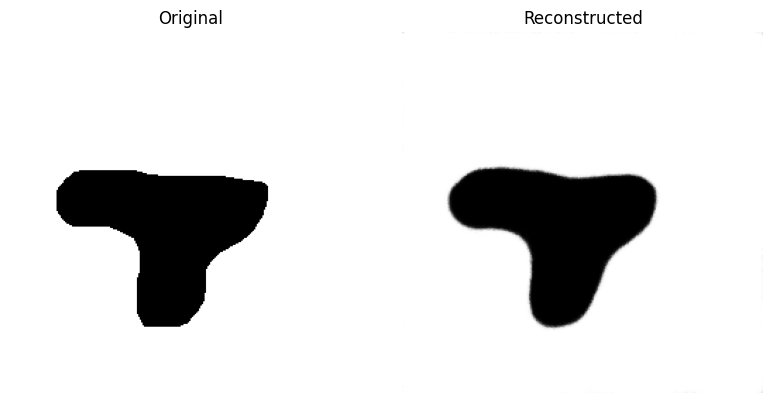

In [54]:
vae= VAE(input_path="/caa/Homes01/alaczko/Diploma/Diploma/data/rocopot_rim_256", f=4, n=3, s=1, k=128)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

vae.to(device)

vae.load_state_dict(torch.load("../models/feature_learning/roco_all_og.pt", map_location=device))

#making sure the formula is correct
transform = transforms.Compose([
    transforms.Grayscale(num_output_channels=1),
    transforms.ToTensor(),
])

img_path = "/caa/Homes01/alaczko/Diploma/Diploma/data/test-roco.png"
original_img = Image.open(img_path)
input_tensor = transform(original_img).unsqueeze(0).to(device) #adding batch dim

with torch.no_grad():
    reconstructed, mu, sigma = vae(input_tensor)

orig_np = input_tensor.squeeze().cpu().numpy()
recon_np = reconstructed.squeeze().cpu().numpy()

fig, axes = plt.subplots(1, 2, figsize=(8, 4))
axes[0].imshow(orig_np, cmap='gray', vmin=0, vmax=1)
axes[0].set_title("Original")
axes[0].axis('off')

axes[1].imshow(recon_np, cmap='gray', vmin=0, vmax=1)
axes[1].set_title("Reconstructed")
axes[1].axis('off')

plt.tight_layout()
plt.show()

### Clustering

In [2]:
df = pd.read_csv("../data/pipeline/roco_run/features.csv")

In [3]:
import numpy as np
import ast

def parse_feature_string(s):
    if isinstance(s, str):
        cleaned = s.strip('[]')
        # tetszőleges mennyiségű whitespace -> egyetlen szóköz
        cleaned = regex_module.sub(r'\s+', ' ', cleaned).strip()
        return np.fromstring(cleaned, sep=' ')
    return np.asarray(s)

In [4]:
df['features'] = df['features'].apply(parse_feature_string)

In [5]:
X = np.vstack(df['features'].values)

# 2. inaktív / szinte nulla varianciájú dimenziók kiszűrése (opcionális, de ajánlott)
variances = X.var(axis=0)
active_dims = variances > 1e-3   # threshold-öt finomítsd a saját adatodra
X_active = X[:, active_dims]

# 3. standardizálás (dimenziónkénti z-score)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_active)

df["features_non_scaled"] = df['features'] 

# 4. opcionálisan visszaírhatod a df-be, hogy egyben tudd kezelni
df['features'] = list(X_scaled)

df.to_csv("../data/pipeline/roco_run/features_scaled.csv", index=False)

In [6]:
df.head()

,filename,features,features_non_scaled
0,BERT11-100b.png,"[-0.4591889344444607, -0.3811585452720912, -1....","[-0.67233, -0.28367, -1.7104, 2.5618, 1.4396, ..."
1,BERT11-101.png,"[-0.9307559124131908, -0.7066401604360796, -2....","[-1.198, -0.62523, -2.2841, 1.8371, 0.31463, 0..."
2,BERT11-102.png,"[-0.7964633398830504, -0.4842842637199389, -2....","[-1.0483, -0.39189, -2.2423, 2.3464, 0.4346, 1..."
3,BERT11-103.png,"[-0.616662001792095, -1.6070319326576445, -1.0...","[-0.84787, -1.5701, -1.0696, 2.5938, -0.013319..."
4,BERT11-104.png,"[-0.9327294839533798, -0.26644523916645557, -2...","[-1.2002, -0.16329, -2.124, 2.1455, 1.3306, 0...."


In [7]:
clustering_step = HierarchicalClustering(
    input_path="../data/pipeline/roco_run/features_scaled.csv",
    cluster_num=55
)
# result= clustering_step.run()


#result = clustering_step.compare_all()

Output path for step HierarchicalClustering : ../data/pipeline/default_run/ClusteringStep/HierarchicalClustering


In [8]:
result= clustering_step.run()

In [9]:
np.unique(result, return_counts=True)

(array([ 1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55], dtype=int32),
 array([   7,   10,    2,    3,    1,    1,    1,    1,    4,    9,    3,    3,   12,   15,    4,    5,    1,    1,    8,   15,    7,    3,   11,    6,   37,   44,   54,    1,  380,  117,   77,   53,   36, 2335,   65,  365,    5,  460,   18,  193,   12,   31,   52,    2,   96,    7,    9,    4,    1,    7,    6,   17,
           1,    1,    1]))

In [10]:
df["pred"] = list(result)

In [11]:
df["filename"] = df["filename"].str.rsplit(".", n=1).str[0]

In [5]:
roco_labels = pd.read_csv("/caa/Homes01/alaczko/Diploma/Diploma/data/rocopot_results.csv")

In [13]:
new_df = pd.merge(
    df,
    roco_labels,
    left_on="filename",
    right_on="ID",
    how="inner"
)

In [14]:
new_df = new_df.dropna(subset=["pred", "TypeRev"]).reset_index(drop=True)

In [15]:
new_df

,filename,features,features_non_scaled,pred,ID,TypeRev,source_sheet
0,BERT11-100b,"[-0.4591889344444607, -0.3811585452720912, -1....","[-0.67233, -0.28367, -1.7104, 2.5618, 1.4396, ...",40,BERT11-100b,pan,BERT11
1,BERT11-101,"[-0.9307559124131908, -0.7066401604360796, -2....","[-1.198, -0.62523, -2.2841, 1.8371, 0.31463, 0...",40,BERT11-101,pan,BERT11
2,BERT11-102,"[-0.7964633398830504, -0.4842842637199389, -2....","[-1.0483, -0.39189, -2.2423, 2.3464, 0.4346, 1...",40,BERT11-102,pan,BERT11
3,BERT11-103,"[-0.616662001792095, -1.6070319326576445, -1.0...","[-0.84787, -1.5701, -1.0696, 2.5938, -0.013319...",36,BERT11-103,pan,BERT11
4,BERT11-104,"[-0.9327294839533798, -0.26644523916645557, -2...","[-1.2002, -0.16329, -2.124, 2.1455, 1.3306, 0....",40,BERT11-104,pan,BERT11
...,...,...,...,...,...,...,...
4592,STAN01-9.I2FF9.246,"[-0.17702202887578766, 0.09054965920831015, 2....","[-0.35779, 0.21134, 2.3581, 1.1562, 1.5436, 0....",38,STAN01-9.I2FF9.246,lid,STAN01
4593,STAN01-9.I2FF9.247,"[0.37808982070103847, -0.8402404720826167, -1....","[0.26101, -0.76543, -1.2004, 2.4863, 0.086412,...",36,STAN01-9.I2FF9.247,lid,STAN01
4594,STAN01-9.I2FF9.248,"[0.03624928838082939, -0.8031620974309279, -0....","[-0.12005, -0.72652, -0.15221, 2.1776, 0.53842...",36,STAN01-9.I2FF9.248,lid,STAN01
4595,STAN01-9.I2FF9.249,"[0.01886391726770902, 0.30844585935878904, 0.9...","[-0.13943, 0.44, 0.91541, 1.3445, 1.0264, 0.37...",38,STAN01-9.I2FF9.249,lid,STAN01


In [16]:
eval_step = EvaluationWithGroundTruth(y_true=new_df["TypeRev"].values, y_pred=new_df["pred"].values)

Ground truth labels: ['pan' 'pan' 'pan' ... 'lid' 'lid' 'dish-lid']
Predicted labels: [40 40 40 ... 36 38 38]


In [17]:
eval_step.run()

-----
Evaluation results: 
ACC = 0.28322819229932567, 
ARI = 0.06986641230531142, 
NMI = 0.16907422690069215
-----




In [3]:
features_path = "../data/pipeline/roco_run/features_scaled.csv"

cluster_numbers = range(10, 100)
metric_results = []

# A features.csv sorrendjében találhatók a klaszterezés bemenetei
features_df = pd.read_csv(features_path)

features_df["filename"] = (
    features_df["filename"]
    .astype(str)
    .str.strip()
    .str.rsplit(".", n=1)
    .str[0]
)


In [6]:
for cluster_num in cluster_numbers:
    clustering_step = HierarchicalClustering(
        input_path=features_path,
        cluster_num=cluster_num
    )

    predicted_labels = clustering_step.run()

    predictions_df = features_df[["filename"]].copy()
    predictions_df["pred"] = predicted_labels

    # Az új klasztercímkék hozzárendelése a meglévő dataframe-hez
    current_df = pd.merge(
        predictions_df,
        roco_labels,
        left_on="filename",
        right_on="ID",
        how="inner"
    )

    current_df = current_df.dropna(subset=["pred", "TypeRev"]).reset_index(drop=True)

    y_true = current_df["TypeRev"].to_numpy()
    y_pred = current_df["pred"].to_numpy()


    eval_step = EvaluationWithGroundTruth(y_true=y_true, y_pred=y_pred)

    eval_step.run()

    metric_results.append({
        "cluster_num": cluster_num,
        "ACC": eval_step.acc,
        "ARI": eval_step.ari,
        "NMI": eval_step.nmi,
        "sample_count": len(current_df),
        "predicted_cluster_count": current_df["pred"].nunique(),
    })

metrics_df = pd.DataFrame(metric_results)
metrics_df

Output path for step HierarchicalClustering : ../data/pipeline/default_run/ClusteringStep/HierarchicalClustering
Ground truth labels: ['pan' 'pan' 'pan' ... 'lid' 'lid' 'dish-lid']
Predicted labels: [7 7 7 ... 7 7 7]
-----
Evaluation results: 
ACC = 0.24559495323036762, 
ARI = 0.001623747771687855, 
NMI = 0.02557106539280918
-----


Output path for step HierarchicalClustering : ../data/pipeline/default_run/ClusteringStep/HierarchicalClustering
Ground truth labels: ['pan' 'pan' 'pan' ... 'lid' 'lid' 'dish-lid']
Predicted labels: [7 7 7 ... 7 7 7]
-----
Evaluation results: 
ACC = 0.24559495323036762, 
ARI = 0.0016835426398254677, 
NMI = 0.025981456670482135
-----


Output path for step HierarchicalClustering : ../data/pipeline/default_run/ClusteringStep/HierarchicalClustering
Ground truth labels: ['pan' 'pan' 'pan' ... 'lid' 'lid' 'dish-lid']
Predicted labels: [8 8 8 ... 8 8 8]
-----
Evaluation results: 
ACC = 0.24559495323036762, 
ARI = 0.0016825870909378791, 
NMI = 0.02611236121920433


,cluster_num,ACC,ARI,NMI,sample_count,predicted_cluster_count
0,10,0.245595,0.001624,0.025571,4597,10
1,11,0.245595,0.001684,0.025981,4597,11
2,12,0.245595,0.001683,0.026112,4597,12
3,13,0.246248,0.001699,0.030511,4597,13
4,14,0.246248,0.001699,0.030836,4597,14
...,...,...,...,...,...,...
85,95,0.250598,0.090253,0.188677,4597,94
86,96,0.249946,0.090225,0.188962,4597,95
87,97,0.249728,0.090214,0.189224,4597,96
88,98,0.249728,0.090214,0.189317,4597,97


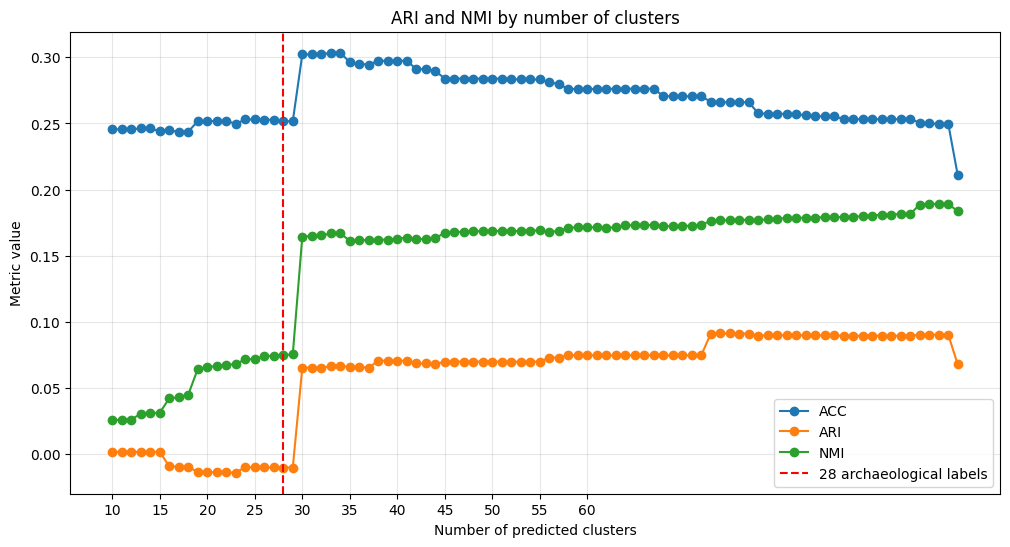

In [7]:
plt.figure(figsize=(12, 6))

plt.plot(
    metrics_df["cluster_num"],
    metrics_df["ACC"],
    marker="o",
    label="ACC"
)

plt.plot(
    metrics_df["cluster_num"],
    metrics_df["ARI"],
    marker="o",
    label="ARI"
)

plt.plot(
    metrics_df["cluster_num"],
    metrics_df["NMI"],
    marker="o",
    label="NMI"
)

plt.axvline(
    28,
    color="red",
    linestyle="--",
    label="28 archaeological labels"
)

plt.xlabel("Number of predicted clusters")
plt.ylabel("Metric value")
plt.title("ARI and NMI by number of clusters")
plt.xticks(range(10, 61, 5))
plt.grid(alpha=0.3)
plt.legend()
plt.show()

In [68]:
new_df

,filename,features,pred,ID,TypeRev,source_sheet
0,BERT11-100b,"[-0.19289996758233602, -1.9181999384417918, 1....",24,BERT11-100b,pan,BERT11
1,BERT11-101,"[0.29380993900889063, -1.5297999601361898, 1.0...",24,BERT11-101,pan,BERT11
2,BERT11-102,"[0.18206996045389146, -0.8582599976456027, 0.1...",24,BERT11-102,pan,BERT11
3,BERT11-103,"[-0.43268992156213976, -0.1836700353253758, -0...",24,BERT11-103,pan,BERT11
4,BERT11-104,"[-0.6141798867308063, -1.8690999411843123, 1.6...",24,BERT11-104,pan,BERT11
...,...,...,...,...,...,...
78,BERT11-96b,"[0.29508993876323464, 0.11721994786816853, 1.3...",25,BERT11-96b,pot,BERT11
79,BERT11-97a,"[-0.6539098791058745, 0.6328899190650012, 2.32...",24,BERT11-97a,pan,BERT11
80,BERT11-97b,"[0.3809899222774143, 0.2549799401734717, 2.364...",24,BERT11-97b,pan,BERT11
81,BERT11-98b,"[0.10013997617779437, -0.032326043778818016, 1...",24,BERT11-98b,pan,BERT11


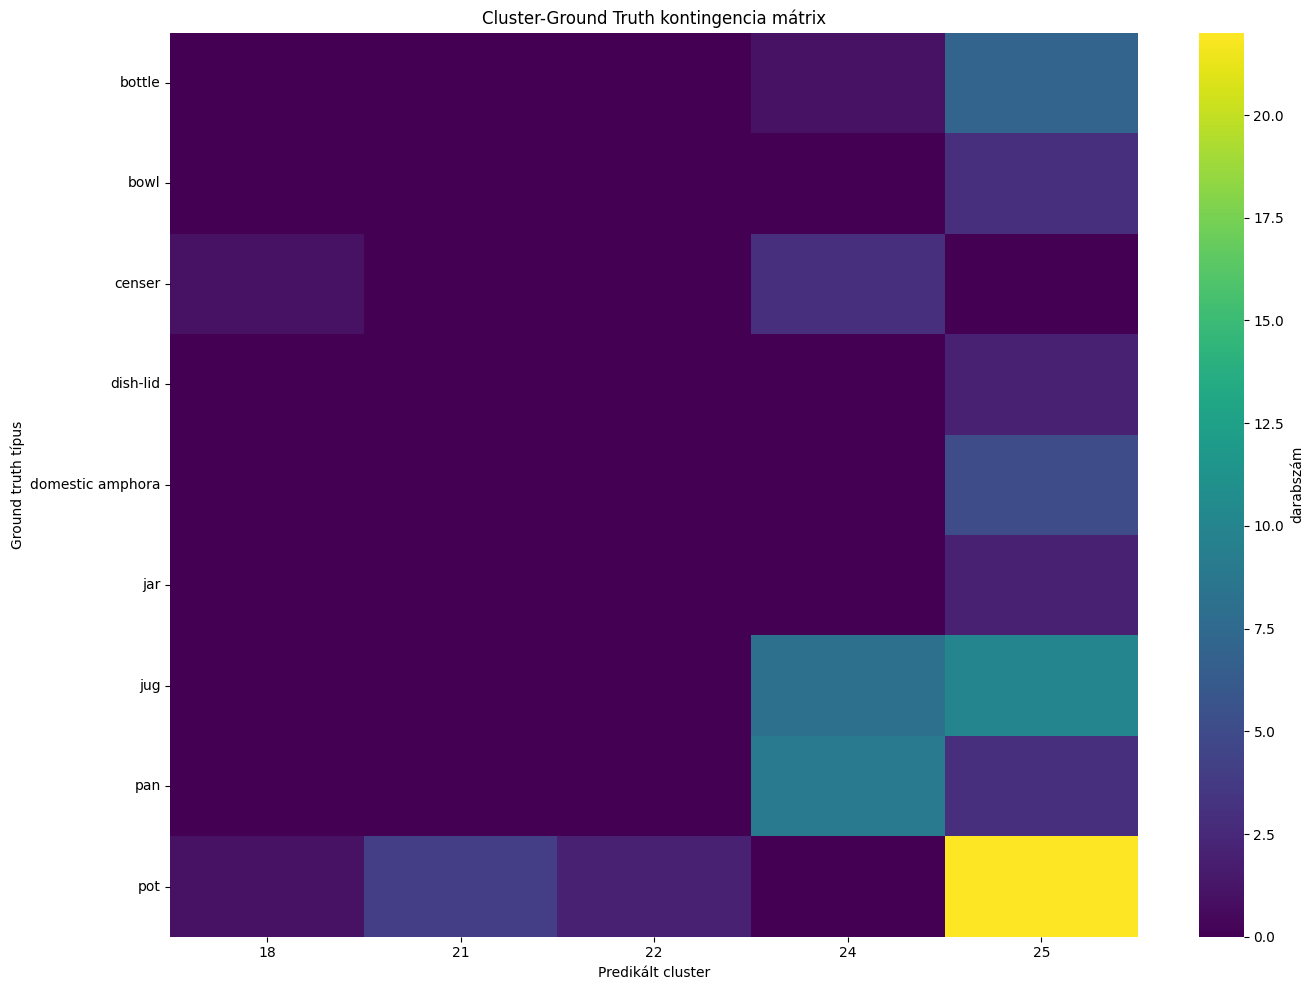

In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# df-ben legyen egy 'pred' (predikált cluster) és egy 'true_label' (ground truth) oszlop
contingency = pd.crosstab(new_df['TypeRev'], new_df['pred'])

plt.figure(figsize=(14, 10))
sns.heatmap(contingency, annot=False, cmap='viridis', cbar_kws={'label': 'darabszám'})
plt.xlabel('Predicted cluster')
plt.ylabel('Ground truth type')
plt.title('Cluster-Ground Truth contingency matrix')
plt.tight_layout()
plt.show()